# Evaluación del detector de placas `license_plate_detector.pt`

Este cuaderno mide **qué tan bien encuentra placas** el detector del motor ANPR (YOLO26n afinado en
Open Images V7, ver `models/MODEL_CARD.md`). Solo evalúa la **detección** (dónde está la placa); la
lectura de los caracteres (OCR) y el sistema completo se miden aparte con
`scripts/evaluar_secuencias.py` (90,6 % de lectura exacta en el video de la garita, 28-10-2026).

**Métricas**

| Métrica | Pregunta que responde |
|---|---|
| Precisión = TP / (TP + FP) | De lo que el detector marcó como placa, ¿cuánto era placa? |
| Recall (exhaustividad) = TP / (TP + FN) | De las placas que había, ¿cuántas encontró? |
| F1 | Media armónica de precisión y recall (un solo número a un umbral) |
| AP50 | Área bajo la curva precisión–recall con IoU ≥ 0,5 (todos los umbrales a la vez) |
| mAP50-95 | AP promedio con IoU de 0,50 a 0,95: exige además cajas bien ajustadas |
| IoU | Solapamiento entre la caja predicha y la etiquetada (1 = idéntica) |

**Protocolo** (el mismo de `scripts/evaluate_detectors.py`, con el que se hizo la ficha del modelo):
imágenes a 512 px (la resolución del servicio), una detección es correcta si su IoU con una placa
etiquetada es ≥ 0,5, y las detecciones se emparejan de la más confiable a la menos confiable (cada
placa cuenta una sola vez). El umbral de confianza del servicio es **0,22**
(`PLATE_CONFIDENCE_THRESHOLD`): bajo para no perder placas, porque el seguimiento y el OCR descartan
después lo que no es placa.

**Datos**

1. **Open Images V7, partición de prueba** (2 048 imágenes, 2 816 placas de todo el mundo, CC BY 2.0).
   El modelo no la vio al entrenar: mide la generalización.
2. **Prueba ecuatoriana real** (105 fotos, 101 placas). Solo dos placas y una habitación: detecta
   regresiones con placas ecuatorianas, pero no estima la precisión general en Ecuador. Contiene
   placas reales: el cuaderno solo muestra cifras de este conjunto, nunca sus imágenes.

**Cómo ejecutarlo** (desde `services/anpr`, unos 5 minutos en CPU la primera vez; las predicciones se
guardan en `dataset/preds/` y las corridas siguientes tardan segundos):

```bash
.venv-train/Scripts/python -m pip install ipykernel nbconvert   # una sola vez
.venv-train/Scripts/python -m nbconvert --to notebook --execute --inplace notebooks/evaluar_detector_placas.ipynb
```

También se puede abrir en VS Code eligiendo el intérprete `services/anpr/.venv-train` como kernel.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import pickle
import platform
import time
from datetime import datetime
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"   # sin barras de progreso de Ultralytics en la salida

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from ultralytics import YOLO

# Raíz del repositorio (el cuaderno puede abrirse desde cualquier carpeta del proyecto)
RAIZ = Path.cwd().resolve()
while not (RAIZ / "services" / "anpr").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
MOTOR = RAIZ / "services" / "anpr"

MODELO = MOTOR / "models" / "license_plate_detector.pt"
SHA_FICHA = "3667d8168e8a5a62fddf0992546efa0dc60f37578c9e95e8c0cbc92d4ed74c5c"  # MODEL_CARD.md
CONJUNTOS = {
    "Open Images V7 (prueba)": RAIZ / "dataset" / "openimages_plates",
    "Ecuador real (piloto)": RAIZ / "dataset" / "prueba_ecuador_real",
}
PRIVADOS = {"Ecuador real (piloto)"}  # placas reales: no se muestran sus imágenes
SPLIT = "test"
IMGSZ = 512              # resolución de inferencia del servicio
UMBRAL_SERVICIO = 0.22   # PLATE_CONFIDENCE_THRESHOLD del motor
UMBRAL_FICHA = 0.35      # umbral de la tabla principal de MODEL_CARD.md
IOU_MIN = 0.5
UMBRALES_IOU = np.round(np.arange(0.50, 0.96, 0.05), 2)   # para mAP50-95
CONF_MIN = 0.01          # se guardan casi todas las detecciones para trazar las curvas
REMUESTREOS = 2000       # bootstrap por imagen
VALIDAR_CON_ULTRALYTICS = True   # segunda medición independiente (model.val), unos minutos más
CACHE = RAIZ / "dataset" / "preds"
SALIDA = RAIZ / "docs" / "resultados" / f"evaluacion_detector_notebook_{datetime.now():%Y-%m-%d}.json"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
rng = np.random.default_rng(0)

## 1. Trazabilidad: modelo y entorno

El SHA-256 debe coincidir con el de la ficha; si no, se está evaluando otro archivo.

In [2]:
sha = hashlib.sha256(MODELO.read_bytes()).hexdigest()
modelo = YOLO(str(MODELO))
entorno = {
    "modelo": str(MODELO.relative_to(RAIZ)).replace("\\", "/"),
    "sha256": sha,
    "coincide_con_ficha": sha == SHA_FICHA,
    "clases": modelo.names,
    "python": platform.python_version(),
    "torch": torch.__version__,
    "ultralytics": ultralytics.__version__,
    "cpu": platform.processor() or platform.machine(),
    "hilos_torch": torch.get_num_threads(),
    "fecha": datetime.now().isoformat(timespec="seconds"),
}
for k, v in entorno.items():
    print(f"{k:20s} {v}")
print("\nSHA-256:", "COINCIDE con MODEL_CARD.md" if entorno["coincide_con_ficha"] else "DISTINTO de MODEL_CARD.md: revise qué modelo se evalúa")

modelo               services/anpr/models/license_plate_detector.pt
sha256               3667d8168e8a5a62fddf0992546efa0dc60f37578c9e95e8c0cbc92d4ed74c5c
coincide_con_ficha   True
clases               {0: 'license_plate'}
python               3.13.1
torch                2.14.0+cpu
ultralytics          8.4.160
cpu                  Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
hilos_torch          14
fecha                2026-10-29T02:15:20

SHA-256: COINCIDE con MODEL_CARD.md


## 2. Datos de prueba

Etiquetas en formato YOLO (`clase cx cy ancho alto`, normalizadas); se convierten a píxeles de la imagen.

In [3]:
def leer_conjunto(carpeta: Path, split: str = SPLIT) -> list[dict]:
    items = []
    for ruta in sorted((carpeta / "images" / split).iterdir()):
        if ruta.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        with Image.open(ruta) as im:
            w, h = im.size
        cajas = []
        etiqueta = carpeta / "labels" / split / f"{ruta.stem}.txt"
        for linea in (etiqueta.read_text().splitlines() if etiqueta.exists() else []):
            if linea.strip():
                _, cx, cy, bw, bh = map(float, linea.split())
                cajas.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
        items.append({"ruta": ruta, "ancho": w, "alto": h, "gt": np.array(cajas, dtype=float).reshape(-1, 4)})
    return items


datos = {nombre: leer_conjunto(carpeta) for nombre, carpeta in CONJUNTOS.items()}
filas = []
for nombre, items in datos.items():
    anchos = np.concatenate([it["gt"][:, 2] - it["gt"][:, 0] for it in items])
    filas.append({
        "conjunto": nombre, "imágenes": len(items), "placas": len(anchos),
        "imágenes sin placa": sum(len(it["gt"]) == 0 for it in items),
        "ancho de placa p50 (px)": round(float(np.median(anchos)), 1),
        "ancho p10–p90 (px)": f"{np.percentile(anchos, 10):.0f}–{np.percentile(anchos, 90):.0f}",
    })
pd.DataFrame(filas).set_index("conjunto")

,imágenes,placas,imágenes sin placa,ancho de placa p50 (px),ancho p10–p90 (px)
conjunto,,,,,
Open Images V7 (prueba),2048,2816,0,60.0,12–144
Ecuador real (piloto),105,101,4,202.7,111–404


## 3. Inferencia

Se guardan todas las detecciones con confianza ≥ 0,01 y el tiempo por imagen (PyTorch en CPU, incluye pre y posproceso). Las predicciones quedan en caché por modelo, conjunto y resolución.

In [4]:
def inferir(nombre: str, items: list[dict]) -> list[dict]:
    clave = f"{sha[:12]}_{CONJUNTOS[nombre].name}_{SPLIT}_{IMGSZ}_{CONF_MIN}"
    archivo = CACHE / f"notebook_{clave}.pkl"
    if archivo.exists():
        guardado = pickle.loads(archivo.read_bytes())
        print(f"{nombre}: predicciones en caché ({archivo.name})")
    else:
        modelo.predict(cv2.imread(str(items[0]["ruta"])), conf=CONF_MIN, imgsz=IMGSZ, verbose=False, device="cpu")  # calentamiento
        guardado, inicio = [], time.perf_counter()
        for it in items:
            img = cv2.imread(str(it["ruta"]))
            t0 = time.perf_counter()
            r = modelo.predict(img, conf=CONF_MIN, imgsz=IMGSZ, verbose=False, device="cpu")[0]
            ms = (time.perf_counter() - t0) * 1000
            guardado.append({"cajas": r.boxes.xyxy.cpu().numpy().astype(float), "conf": r.boxes.conf.cpu().numpy().astype(float), "ms": ms})
        CACHE.mkdir(parents=True, exist_ok=True)
        archivo.write_bytes(pickle.dumps(guardado))
        print(f"{nombre}: {len(items)} imágenes en {time.perf_counter() - inicio:.0f} s")
    for it, p in zip(items, guardado):
        it.update(p)
    return items


for nombre, items in datos.items():
    inferir(nombre, items)

Open Images V7 (prueba): predicciones en caché (notebook_3667d8168e8a_openimages_plates_test_512_0.01.pkl)
Ecuador real (piloto): predicciones en caché (notebook_3667d8168e8a_prueba_ecuador_real_test_512_0.01.pkl)


## 4. Emparejamiento detección ↔ placa

Para cada imagen se calcula el IoU de cada detección con cada placa. Las detecciones se recorren de
mayor a menor confianza y cada una toma la placa libre con la que más se solapa; si ese IoU es
≥ al mínimo, es un acierto (TP) y la placa queda usada; si no, es un falso positivo (FP). Las placas
que nadie tomó son falsos negativos (FN). Como se recorre por confianza, el resultado a cualquier
umbral es el mismo que si se hubieran descartado antes las detecciones por debajo de él.

In [5]:
def matriz_iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda c: (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)


def emparejar(conf: np.ndarray, iou: np.ndarray, minimo: float):
    # Devuelve, por detección, si acertó y con qué IoU; por placa, la confianza de quien la detectó (-1 = nadie)
    acierto = np.zeros(len(conf), bool)
    iou_acierto = np.zeros(len(conf))
    conf_placa = np.full(iou.shape[1], -1.0)
    libre = np.ones(iou.shape[1], bool)
    for i in np.argsort(-conf, kind="stable"):
        if not libre.any():
            break
        candidatos = np.where(libre, iou[i], -1.0)
        j = int(np.argmax(candidatos))
        if candidatos[j] >= minimo:
            libre[j] = False
            acierto[i], iou_acierto[i], conf_placa[j] = True, candidatos[j], conf[i]
    return acierto, iou_acierto, conf_placa


def evaluar(items: list[dict], minimo: float = IOU_MIN) -> dict:
    det_conf, det_ok, det_iou, det_img, placa_conf, placa_img, placa_ancho = [], [], [], [], [], [], []
    for k, it in enumerate(items):
        iou = matriz_iou(it["cajas"], it["gt"])
        ok, v, cp = emparejar(it["conf"], iou, minimo)
        det_conf.append(it["conf"]); det_ok.append(ok); det_iou.append(v); det_img.append(np.full(len(ok), k))
        placa_conf.append(cp); placa_img.append(np.full(len(cp), k)); placa_ancho.append(it["gt"][:, 2] - it["gt"][:, 0])
    cat = lambda x: np.concatenate(x) if x else np.array([])
    return {"det_conf": cat(det_conf), "det_ok": cat(det_ok).astype(bool), "det_iou": cat(det_iou), "det_img": cat(det_img).astype(int),
            "placa_conf": cat(placa_conf), "placa_img": cat(placa_img).astype(int), "placa_ancho": cat(placa_ancho), "imagenes": len(items)}


resultados = {nombre: evaluar(items) for nombre, items in datos.items()}

## 5. Precisión, recall y F1 a un umbral de confianza

In [6]:
def metricas(r: dict, umbral: float) -> dict:
    sel = r["det_conf"] >= umbral
    tp = int(r["det_ok"][sel].sum()); fp = int(sel.sum()) - tp; fn = len(r["placa_conf"]) - tp
    p = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f1 = 2 * p * rec / max(p + rec, 1e-12)
    return {"umbral": umbral, "TP": tp, "FP": fp, "FN": fn, "precisión": p, "recall": rec, "F1": f1}


def umbral_f1_maximo(r: dict) -> float:
    candidatos = np.unique(np.round(r["det_conf"], 3))
    return float(max(candidatos, key=lambda u: metricas(r, u)["F1"]))


tablas = []
for nombre, r in resultados.items():
    for u in (UMBRAL_SERVICIO, UMBRAL_FICHA, umbral_f1_maximo(r)):
        tablas.append({"conjunto": nombre, **metricas(r, u)})
tabla_umbral = pd.DataFrame(tablas).drop_duplicates(["conjunto", "umbral"])
tabla_umbral.style.format({"umbral": "{:.2f}", "precisión": "{:.1%}", "recall": "{:.1%}", "F1": "{:.3f}"}).hide(axis="index")

conjunto,umbral,TP,FP,FN,precisión,recall,F1
Open Images V7 (prueba),0.22,2359,340,457,87.4%,83.8%,0.855
Open Images V7 (prueba),0.35,2296,151,520,93.8%,81.5%,0.873
Open Images V7 (prueba),0.38,2281,127,535,94.7%,81.0%,0.873
Ecuador real (piloto),0.22,86,9,15,90.5%,85.1%,0.878
Ecuador real (piloto),0.35,81,6,20,93.1%,80.2%,0.862
Ecuador real (piloto),0.18,88,10,13,89.8%,87.1%,0.884


**Cómo leerla.** Con el umbral del servicio (0,22) el detector prioriza el recall: deja pasar más
falsos positivos (rótulos, adoquines, marcos) que después filtran la zona de interés, el seguimiento,
el formato ANT y el segundo OCR. Subir el umbral sube la precisión pero pierde placas que ya no se
pueden recuperar en etapas posteriores.

## 6. Curvas: precisión–recall y métricas según el umbral

AP se calcula con interpolación de todos los puntos (la misma de la ficha; ver Padilla et al., 2020, sobre las variantes de AP).

In [7]:
def curva_pr(r: dict):
    orden = np.argsort(-r["det_conf"], kind="stable")
    ok = r["det_ok"][orden]
    tp = np.cumsum(ok); fp = np.cumsum(~ok)
    recall = tp / max(len(r["placa_conf"]), 1)
    precision = tp / np.maximum(tp + fp, 1e-12)
    return r["det_conf"][orden], precision, recall


def precision_media(precision: np.ndarray, recall: np.ndarray) -> float:
    mrec = np.concatenate([[0.0], recall, [1.0]])
    mpre = np.concatenate([[1.0], precision, [0.0]])
    mpre = np.maximum.accumulate(mpre[::-1])[::-1]   # envolvente decreciente
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1]))


ap = {}
for nombre, items in datos.items():
    por_iou = {}
    for t in UMBRALES_IOU:
        r_t = resultados[nombre] if t == IOU_MIN else evaluar(items, float(t))
        _, p, rc = curva_pr(r_t)
        por_iou[float(t)] = precision_media(p, rc)
    ap[nombre] = {"AP50": por_iou[0.5], "AP75": por_iou[0.75], "mAP50-95": float(np.mean(list(por_iou.values()))), "por_iou": por_iou}
pd.DataFrame({n: {k: v for k, v in a.items() if k != "por_iou"} for n, a in ap.items()}).T.style.format("{:.3f}")

,AP50,AP75,mAP50-95
Open Images V7 (prueba),0.862,0.605,0.536
Ecuador real (piloto),0.883,0.390,0.422


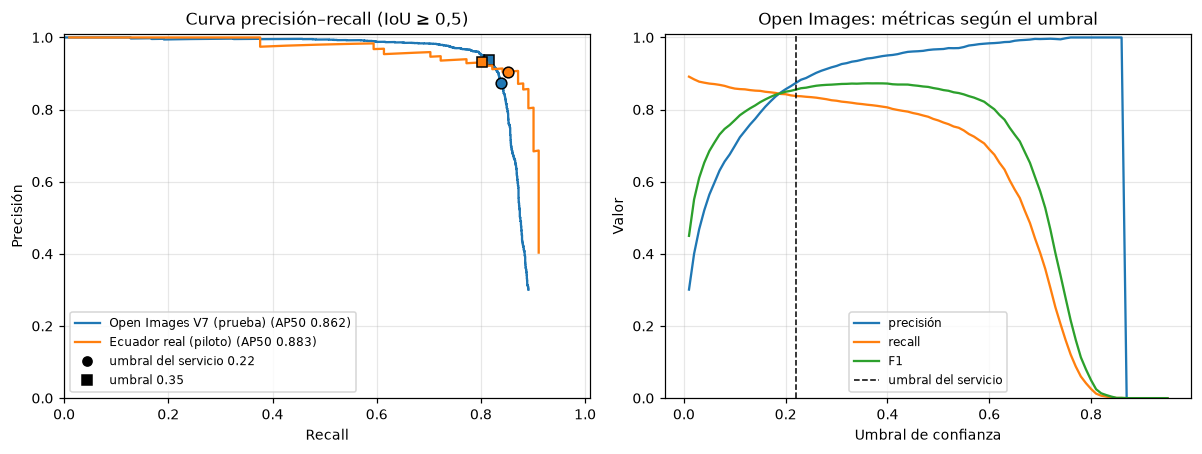

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for nombre, r in resultados.items():
    conf, p, rc = curva_pr(r)
    linea, = ejes[0].plot(rc, p, label=f"{nombre} (AP50 {ap[nombre]['AP50']:.3f})")
    for u, marca in ((UMBRAL_SERVICIO, "o"), (UMBRAL_FICHA, "s")):
        m = metricas(r, u)
        ejes[0].plot(m["recall"], m["precisión"], marca, color=linea.get_color(), ms=7, mec="k")
ejes[0].set(xlabel="Recall", ylabel="Precisión", title="Curva precisión–recall (IoU ≥ 0,5)", xlim=(0, 1.01), ylim=(0, 1.01))
ejes[0].plot([], [], "ko", label=f"umbral del servicio {UMBRAL_SERVICIO}"); ejes[0].plot([], [], "ks", label=f"umbral {UMBRAL_FICHA}")
ejes[0].legend(loc="lower left", fontsize=8)

r = resultados["Open Images V7 (prueba)"]
umbrales = np.linspace(0.01, 0.95, 95)
curvas = pd.DataFrame([metricas(r, u) for u in umbrales])
for col in ("precisión", "recall", "F1"):
    ejes[1].plot(curvas["umbral"], curvas[col], label=col)
ejes[1].axvline(UMBRAL_SERVICIO, color="k", ls="--", lw=1, label="umbral del servicio")
ejes[1].set(xlabel="Umbral de confianza", ylabel="Valor", title="Open Images: métricas según el umbral", ylim=(0, 1.01))
ejes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Intervalos de confianza (bootstrap por imagen)

Se remuestrean imágenes con reposición; el intervalo del 95 % dice cuánto podrían variar las cifras con otra muestra del mismo tipo de imágenes.

In [9]:
def bootstrap(r: dict, umbral: float, n: int = REMUESTREOS) -> dict:
    sel = r["det_conf"] >= umbral
    imgs = r["imagenes"]
    tp = np.bincount(r["det_img"][sel & r["det_ok"]], minlength=imgs)
    fp = np.bincount(r["det_img"][sel & ~r["det_ok"]], minlength=imgs)
    gt = np.bincount(r["placa_img"], minlength=imgs)
    muestras = rng.integers(0, imgs, size=(n, imgs))
    TP, FP, GT = tp[muestras].sum(1), fp[muestras].sum(1), gt[muestras].sum(1)
    P = TP / np.maximum(TP + FP, 1); R = TP / np.maximum(GT, 1); F = 2 * P * R / np.maximum(P + R, 1e-12)
    ic = lambda x: (float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5)))
    return {"precisión": ic(P), "recall": ic(R), "F1": ic(F)}


ic95 = {nombre: bootstrap(r, UMBRAL_SERVICIO) for nombre, r in resultados.items()}
filas = []
for nombre, r in resultados.items():
    m = metricas(r, UMBRAL_SERVICIO)
    for k in ("precisión", "recall", "F1"):
        filas.append({"conjunto": nombre, "métrica": k, "valor": m[k], "IC 95 % inferior": ic95[nombre][k][0], "IC 95 % superior": ic95[nombre][k][1]})
pd.DataFrame(filas).style.format({c: "{:.3f}" for c in ("valor", "IC 95 % inferior", "IC 95 % superior")}).hide(axis="index")

conjunto,métrica,valor,IC 95 % inferior,IC 95 % superior
Open Images V7 (prueba),precisión,0.874,0.860,0.887
Open Images V7 (prueba),recall,0.838,0.820,0.854
Open Images V7 (prueba),F1,0.855,0.843,0.868
Ecuador real (piloto),precisión,0.905,0.847,0.957
Ecuador real (piloto),recall,0.851,0.780,0.913
Ecuador real (piloto),F1,0.878,0.827,0.925


## 8. ¿Qué placas pierde? Recall según el tamaño de la placa

El ancho en píxeles es el de la imagen original (Open Images está reducida a 640 px por el lado mayor); en la garita el tamaño depende de la distancia y del zoom de la cámara.

conjunto,ancho de la placa,placas,recall
Open Images V7 (prueba),< 20 px,580,38.6%
Open Images V7 (prueba),20–40 px,424,88.7%
Open Images V7 (prueba),40–80 px,800,97.2%
Open Images V7 (prueba),80–160 px,823,97.4%
Open Images V7 (prueba),≥ 160 px,189,94.7%
Ecuador real (piloto),80–160 px,46,73.9%
Ecuador real (piloto),≥ 160 px,55,94.5%


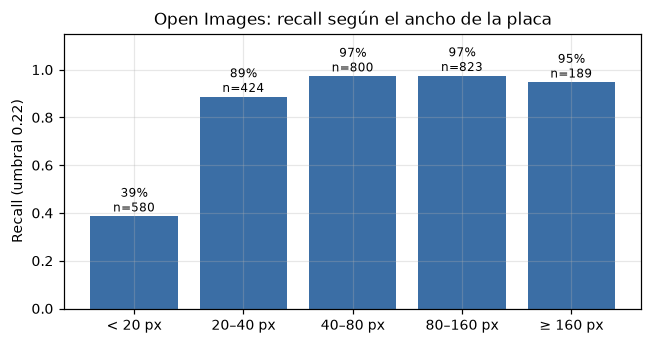

In [10]:
cortes = [0, 20, 40, 80, 160, np.inf]
etiquetas = ["< 20 px", "20–40 px", "40–80 px", "80–160 px", "≥ 160 px"]
filas = []
for nombre, r in resultados.items():
    grupo = pd.cut(r["placa_ancho"], cortes, labels=etiquetas, right=False)
    detectada = r["placa_conf"] >= UMBRAL_SERVICIO
    for g in etiquetas:
        m = grupo == g
        if m.sum():
            filas.append({"conjunto": nombre, "ancho de la placa": g, "placas": int(m.sum()), "recall": float(detectada[m].mean())})
por_tamano = pd.DataFrame(filas)
display(por_tamano.style.format({"recall": "{:.1%}"}).hide(axis="index"))

oi = por_tamano[por_tamano["conjunto"] == "Open Images V7 (prueba)"]
fig, eje = plt.subplots(figsize=(6, 3.2))
eje.bar(oi["ancho de la placa"].astype(str), oi["recall"], color="#3b6ea5")
for x, (rc, n) in enumerate(zip(oi["recall"], oi["placas"])):
    eje.text(x, rc + 0.02, f"{rc:.0%}\nn={n}", ha="center", fontsize=8)
eje.set(ylim=(0, 1.15), ylabel=f"Recall (umbral {UMBRAL_SERVICIO})", title="Open Images: recall según el ancho de la placa")
plt.tight_layout(); plt.show()

## 9. Ajuste de las cajas (IoU de los aciertos) y matriz de confusión

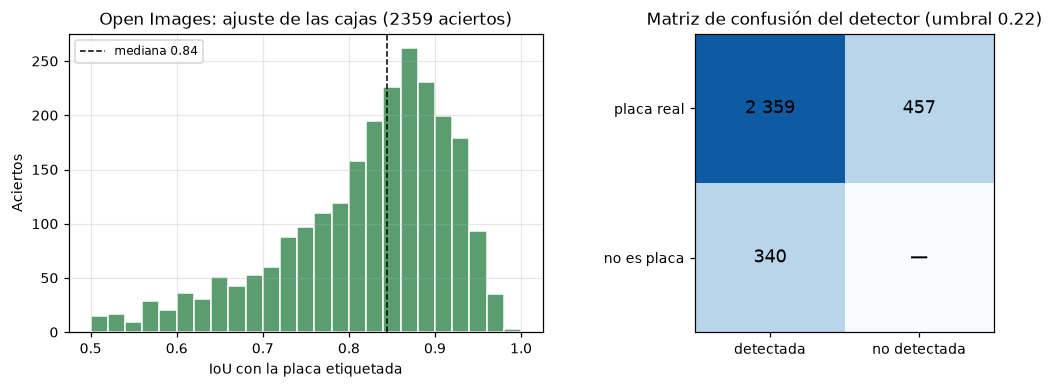

IoU de los aciertos: media 0.821, mediana 0.844, ≥ 0,75 en 79.1%
El fondo bien descartado (verdaderos negativos) no se cuenta: en detección no hay un número finito de 'no placas'.


In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
r = resultados["Open Images V7 (prueba)"]
sel = (r["det_conf"] >= UMBRAL_SERVICIO) & r["det_ok"]
ious = r["det_iou"][sel]
ejes[0].hist(ious, bins=np.linspace(0.5, 1, 26), color="#5a9e6f", edgecolor="white")
ejes[0].axvline(np.median(ious), color="k", ls="--", lw=1, label=f"mediana {np.median(ious):.2f}")
ejes[0].set(xlabel="IoU con la placa etiquetada", ylabel="Aciertos", title=f"Open Images: ajuste de las cajas ({len(ious)} aciertos)")
ejes[0].legend(fontsize=8)

m = metricas(r, UMBRAL_SERVICIO)
matriz = np.array([[m["TP"], m["FN"]], [m["FP"], 0]])
ejes[1].imshow(np.array([[1, 0.35], [0.35, 0]]), cmap="Blues", vmin=0, vmax=1.2)
for (i, j), v in np.ndenumerate(matriz):
    ejes[1].text(j, i, "—" if (i, j) == (1, 1) else f"{v:,}".replace(",", " "), ha="center", va="center", fontsize=12)
ejes[1].set_xticks([0, 1], ["detectada", "no detectada"]); ejes[1].set_yticks([0, 1], ["placa real", "no es placa"])
ejes[1].set_title(f"Matriz de confusión del detector (umbral {UMBRAL_SERVICIO})"); ejes[1].grid(False)
plt.tight_layout(); plt.show()
print(f"IoU de los aciertos: media {ious.mean():.3f}, mediana {np.median(ious):.3f}, ≥ 0,75 en {np.mean(ious >= 0.75):.1%}")
print("El fondo bien descartado (verdaderos negativos) no se cuenta: en detección no hay un número finito de 'no placas'.")

## 10. Ejemplos de errores (solo Open Images)

Verde: placa etiquetada · azul: acierto · rojo: falso positivo. Arriba, los falsos positivos más confiables; abajo, las placas más grandes que no detectó. Imágenes de Open Images V7 (CC BY 2.0 de sus autores).

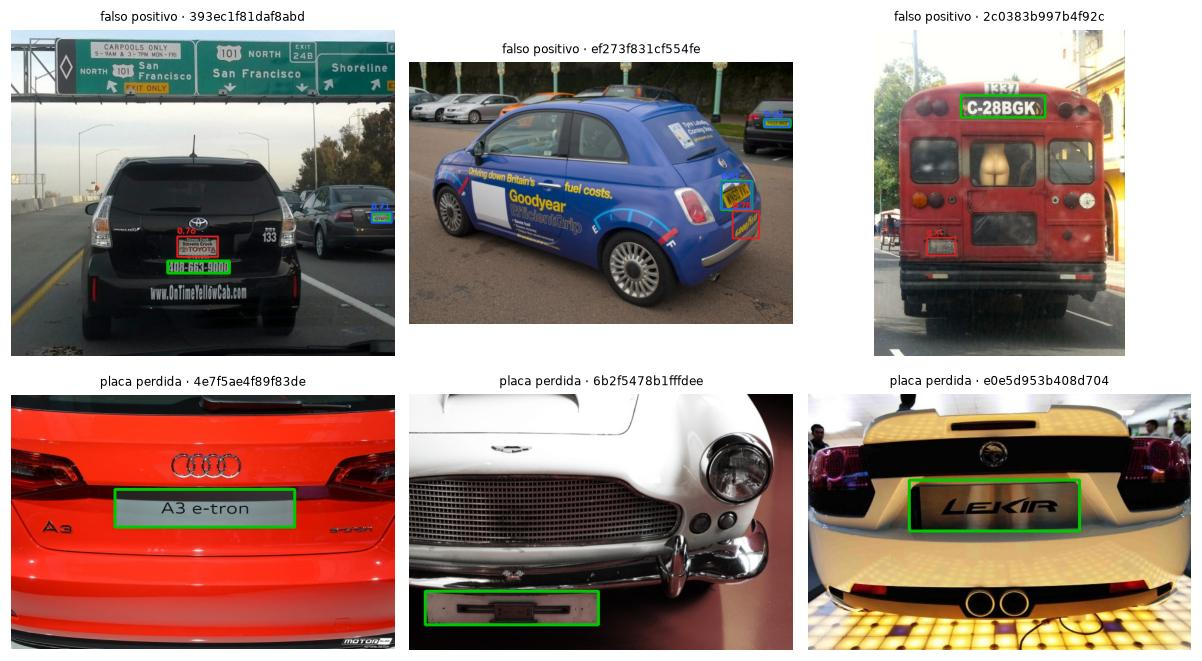

In [12]:
nombre = "Open Images V7 (prueba)"
items, r = datos[nombre], resultados[nombre]
sel = r["det_conf"] >= UMBRAL_SERVICIO
fp_idx = np.where(sel & ~r["det_ok"])[0]
peores_fp = list(dict.fromkeys(r["det_img"][fp_idx[np.argsort(-r["det_conf"][fp_idx])]]))[:3]
fn_idx = np.where(r["placa_conf"] < UMBRAL_SERVICIO)[0]
peores_fn = list(dict.fromkeys(r["placa_img"][fn_idx[np.argsort(-r["placa_ancho"][fn_idx])]]))[:3]

set_matplotlib_formats("jpeg")   # fotos: JPEG pesa mucho menos que PNG en el cuaderno
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.4))
for eje, k, titulo in zip(ejes.flat, peores_fp + peores_fn, ["falso positivo"] * 3 + ["placa perdida"] * 3):
    it = items[k]
    img = cv2.cvtColor(cv2.imread(str(it["ruta"])), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in it["gt"].astype(int):
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 3)
    iou = matriz_iou(it["cajas"], it["gt"])
    ok, _, _ = emparejar(it["conf"], iou, IOU_MIN)
    for (x1, y1, x2, y2), c, bien in zip(it["cajas"].astype(int), it["conf"], ok):
        if c >= UMBRAL_SERVICIO:
            color = (40, 90, 255) if bien else (230, 30, 30)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, f"{c:.2f}", (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    eje.imshow(img); eje.set_title(f"{titulo} · {it['ruta'].stem[:16]}", fontsize=8); eje.axis("off")
plt.tight_layout(); plt.show()
set_matplotlib_formats("png")

**Qué se ve en los errores.** Parte de las «placas perdidas» de Open Images son placas de exhibición
con texto de marca o un portaplacas vacío, y algunos falsos positivos son rótulos de concesionario o
texto pintado en la carrocería. El primer caso es ruido de la etiqueta, no un fallo del detector; el
segundo es el que en el sistema filtran el formato ANT y el segundo OCR. No se cuantificó cuánto del
error total es ruido de etiqueta: para eso habría que revisar a mano una muestra aleatoria de errores.

## 11. Segunda medición independiente: `model.val()` de Ultralytics

Ultralytics calcula AP con interpolación de 101 puntos y su propio emparejamiento, así que sus cifras difieren un poco de las de este cuaderno. Que ambas coincidan en lo grueso confirma que el cálculo propio es correcto.

In [13]:
validacion = None
if VALIDAR_CON_ULTRALYTICS:
    v = modelo.val(data=str(CONJUNTOS["Open Images V7 (prueba)"] / "data.yaml"), split="test", imgsz=IMGSZ, batch=16,
                   device="cpu", plots=False, verbose=False, project=str(CACHE / "val"), name="notebook", exist_ok=True)
    validacion = {"precisión": float(v.box.mp), "recall": float(v.box.mr), "mAP50": float(v.box.map50), "mAP50-95": float(v.box.map)}
    print(f"Ultralytics {ultralytics.__version__} · {len(datos['Open Images V7 (prueba)'])} imágenes")
    print("Precisión y recall al umbral que maximiza F1; AP con interpolación de 101 puntos:")
    for k, x in validacion.items():
        print(f"  {k:10s} {x:.3f}")

Ultralytics 8.4.160 · 2048 imágenes
Precisión y recall al umbral que maximiza F1; AP con interpolación de 101 puntos:
  precisión  0.945
  recall     0.811
  mAP50      0.869
  mAP50-95   0.546


## 12. ¿Se reproduce la ficha del modelo?

Valores de `models/MODEL_CARD.md` (medidos el 01-10-2026 y el 09-10-2026 con `scripts/evaluate_detectors.py`). Diferencias menores de 0,005 se consideran la misma medición.

In [14]:
r = resultados["Open Images V7 (prueba)"]
a22, a35 = metricas(r, UMBRAL_SERVICIO), metricas(r, UMBRAL_FICHA)
comparacion = [
    ("Precisión @0,35", 0.938, a35["precisión"]), ("Recall @0,35", 0.815, a35["recall"]), ("F1 @0,35", 0.873, a35["F1"]),
    ("Precisión @0,22", 0.874, a22["precisión"]), ("Recall @0,22", 0.838, a22["recall"]), ("F1 @0,22", 0.855, a22["F1"]),
    ("AP50 (todos los puntos)", 0.862, ap["Open Images V7 (prueba)"]["AP50"]),
]
if validacion:
    comparacion += [("mAP50 Ultralytics", 0.869, validacion["mAP50"]), ("mAP50-95 Ultralytics", 0.546, validacion["mAP50-95"])]
tabla = pd.DataFrame(comparacion, columns=["métrica", "ficha", "este cuaderno"])
tabla["diferencia"] = tabla["este cuaderno"] - tabla["ficha"]
tabla["¿reproduce?"] = np.where(tabla["diferencia"].abs() < 0.005, "sí", "revisar")
tabla.style.format({"ficha": "{:.3f}", "este cuaderno": "{:.3f}", "diferencia": "{:+.3f}"}).hide(axis="index")

métrica,ficha,este cuaderno,diferencia,¿reproduce?
"Precisión @0,35",0.938,0.938,+0.000,sí
"Recall @0,35",0.815,0.815,+0.000,sí
"F1 @0,35",0.873,0.873,-0.000,sí
"Precisión @0,22",0.874,0.874,+0.000,sí
"Recall @0,22",0.838,0.838,-0.000,sí
"F1 @0,22",0.855,0.855,+0.000,sí
AP50 (todos los puntos),0.862,0.862,+0.000,sí
mAP50 Ultralytics,0.869,0.869,+0.000,sí
mAP50-95 Ultralytics,0.546,0.546,-0.000,sí


## 13. Latencia del detector en este equipo

In [15]:
filas = []
for nombre, items in datos.items():
    ms = np.array([it["ms"] for it in items])
    filas.append({"conjunto": nombre, "imágenes": len(ms), "media (ms)": ms.mean(), "p50 (ms)": np.percentile(ms, 50), "p95 (ms)": np.percentile(ms, 95)})
display(pd.DataFrame(filas).style.format({c: "{:.1f}" for c in ("media (ms)", "p50 (ms)", "p95 (ms)")}).hide(axis="index"))
print("PyTorch en CPU, una imagen a la vez. Si las predicciones vienen de la caché, el tiempo es el de la corrida que la creó.")
print("El servicio usa la exportación OpenVINO (más rápida); los tiempos varían 2–3× entre corridas en este portátil,")
print("así que solo sirven para comparar variantes medidas en la misma corrida (ver docs/METODO_VERIFICACION_LECTURA.md).")

conjunto,imágenes,media (ms),p50 (ms),p95 (ms)
Open Images V7 (prueba),2048,79.1,83.7,109.3
Ecuador real (piloto),105,68.0,66.1,85.4


PyTorch en CPU, una imagen a la vez. Si las predicciones vienen de la caché, el tiempo es el de la corrida que la creó.
El servicio usa la exportación OpenVINO (más rápida); los tiempos varían 2–3× entre corridas en este portátil,
así que solo sirven para comparar variantes medidas en la misma corrida (ver docs/METODO_VERIFICACION_LECTURA.md).


## 14. Resultados guardados

In [16]:
resumen = {
    "entorno": entorno,
    "protocolo": {"split": SPLIT, "imgsz": IMGSZ, "iou_minimo": IOU_MIN, "umbral_servicio": UMBRAL_SERVICIO, "conf_minima_guardada": CONF_MIN,
                  "emparejamiento": "codicioso por confianza (scripts/evaluate_detectors.py)", "ap": "interpolación de todos los puntos"},
    "conjuntos": {},
    "ultralytics_val_open_images": validacion,
}
for nombre, r in resultados.items():
    resumen["conjuntos"][nombre] = {
        "imagenes": r["imagenes"], "placas": int(len(r["placa_conf"])),
        "umbral_servicio": metricas(r, UMBRAL_SERVICIO), "umbral_0_35": metricas(r, UMBRAL_FICHA),
        "umbral_f1_maximo": metricas(r, umbral_f1_maximo(r)), "ic95_umbral_servicio": ic95[nombre],
        "ap": {k: v for k, v in ap[nombre].items() if k != "por_iou"},
        "recall_por_ancho": por_tamano[por_tamano["conjunto"] == nombre][["ancho de la placa", "placas", "recall"]].astype({"ancho de la placa": str}).to_dict("records"),
    }
SALIDA.parent.mkdir(parents=True, exist_ok=True)
SALIDA.write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Guardado en", SALIDA.relative_to(RAIZ).as_posix())

Guardado en docs/resultados/evaluacion_detector_notebook_2026-10-29.json


## 15. Conclusiones y límites

- **Open Images** es la medida de generalización: imágenes de todo el mundo que el modelo no vio. Es
  la cifra que corresponde reportar como precisión y recall del detector.
- **Prueba ecuatoriana:** sirve para comprobar que el detector no empeora con placas ecuatorianas,
  pero tiene solo dos placas y una habitación; sus cifras no son la precisión del sistema en la garita.
- **El detector no es el sistema.** Un falso positivo del detector casi nunca termina en un registro
  falso (lo descartan la zona, el seguimiento, el formato ANT y el segundo OCR), y una placa que el
  detector pierde sí se pierde. Por eso el servicio usa un umbral bajo (0,22).
- **Falta** una prueba etiquetada de la cámara real de la garita (de día, de noche y con lluvia) para
  afirmar la precisión en el lugar de uso; el protocolo está en `docs/PROTOCOLO_EVALUACION_SECUENCIAS.md`.

Referencias de método: R. Padilla, S. L. Netto y E. A. B. da Silva, «A Survey on Performance Metrics
for Object-Detection Algorithms», IWSSIP 2020, DOI 10.1109/IWSSIP48289.2020.9145130; A. Kuznetsova
et al., «The Open Images Dataset V4», *IJCV* 128, 2020, DOI 10.1007/s11263-020-01316-z.